In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.close()
import matplotlib as mpl
from matplotlib import gridspec
import pickle as pickle

from scipy.optimize import curve_fit

import import_ipynb
import ipynb.fs.full.ssiProjectModule as ssiMod
import importlib as imp
imp.reload(ssiMod)

theta_step = 2
stim = np.arange(0,360,theta_step)
main_dir = 'C:/Users/Carlo PARIS/00PhD Code/'

area_or_max = 'Area'
# dat_dir_out = main_dir + f'Simulated Stretch/Analyze stretched quadruplets constrained by AREA or MAX/'
dat_dir_out = main_dir + f'0Paper plots/Figure1/'

title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240509_AREA.pkl'
# title = f'Stretch_BioQuads_multiplied_w_mean_g__theta_step={theta_step}_original_g_20240506_MAX.pkl'


with open(dat_dir_out+title, 'rb') as rick:
    data_dict = pickle.load(rick)


In [2]:
def SCATTER_LEGEND(axis, scatterplot_list, leg_pos, labelcolors=None):
    if labelcolors == None:
        labelcolors = [list(sc.get_facecolor()[0]) for sc in scatterplot_list]
    leg = axis.legend(labelcolor = labelcolors, \
          handlelength = 0, markerscale = 0, frameon=0, loc = leg_pos)
    return

def SMOOTH(y, box_pts):
    box = np.ones(box_pts)/box_pts
    y_smooth = np.convolve(y, box, mode='same')
    return y_smooth

In [3]:
colors=['blue', 'green','red', 'gold' ]
example_quads = [201, 481]
# example_quads = [125,201]
cm = 1/2.54

In [4]:
fwhms = data_dict['all_quad_fwhm'][example_quads]
scatter_marker = ['o', 's']



is_proximal_quad = data_dict['is_bio_quad']
bio_idx = np.where(data_dict['all_multipliers']==1.)[0][0]
maxMin_width_idx = data_dict['all_ssis'].min(axis = 2).argmax(axis=1)
maxAvg_width_idx = data_dict['all_ssis'].mean(axis = 2).argmax(axis=1)

maxMin_width_fwhm = np.array([data_dict['all_quad_fwhm'][i,j] for i,j in enumerate(maxMin_width_idx)])
maxAvg_width_fwhm = np.array([data_dict['all_quad_fwhm'][i,j] for i,j in enumerate(maxAvg_width_idx)])

fwhm = data_dict['all_quad_fwhm'].mean(axis=2)
bio_fwhms = data_dict['all_quad_fwhm'][:,bio_idx,:].round()

maxMin_SSI = np.array([data_dict['all_ssis'].min(axis = 2)[i,el] for i, el in enumerate(maxMin_width_idx)])
maxAvg_SSI = np.array([data_dict['all_ssis'].mean(axis = 2)[i,el] for i, el in enumerate(maxAvg_width_idx)])

# calculate the percantage of loss wirth respect to the global optimum !! 

perc_loss_maxmin = (maxMin_SSI-data_dict['all_ssis'].min(axis=2)[:,bio_idx])#/maxMin_SSI*100
perc_loss_maxavg = (maxAvg_SSI-data_dict['all_ssis'].mean(axis=2)[:,bio_idx])#/maxAvg_SSI*100

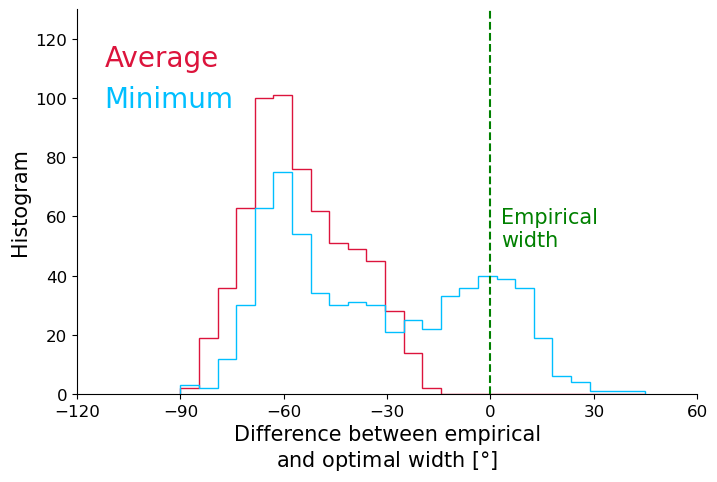

In [110]:
plt.figure(figsize = (8,5))
plt.hist(maxAvg_width_fwhm.mean(axis=1)-bio_fwhms.mean(axis=1), \
        bins = 25, range = (-90, 45), histtype = 'step', color = 'crimson')
plt.plot([0],[0], color = 'crimson', label = 'Average')
plt.hist(maxMin_width_fwhm.mean(axis=1)-bio_fwhms.mean(axis=1), \
        bins = 25, range = (-90, 45), histtype = 'step', color = 'deepskyblue')
plt.plot([0],[0], color = 'deepskyblue', label = 'Minimum')

plt.axvline(0, color = 'green', linestyle = 'dashed')
plt.text(3, 50, 'Empirical\nwidth', color = 'green', size = 15)
plt.xlim(-90, 45)
plt.ylim(0,130)
plt.xticks(np.arange(-120, 61, 30))
plt.yticks(np.arange(0, 121, 20))
# mpl.axes.Axes.tick_params(labelsize)
plt.tick_params(which='both', labelsize=12)

plt.xlabel('Difference between empirical\n'+r'and optimal width [$\degree$]', \
                         size = 15)
plt.ylabel('Histogram',size = 15)

plt.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, loc=(-0.01, 0.7), fontsize = 20)
plt.savefig('C:/Users/Carlo PARIS/Desktop/Thesis/PhD presentation/Images/Width_Diff_optima_global.png',\
           bbox_inches ='tight', dpi=300)

In [37]:
optima_widths_min.shape

(648,)

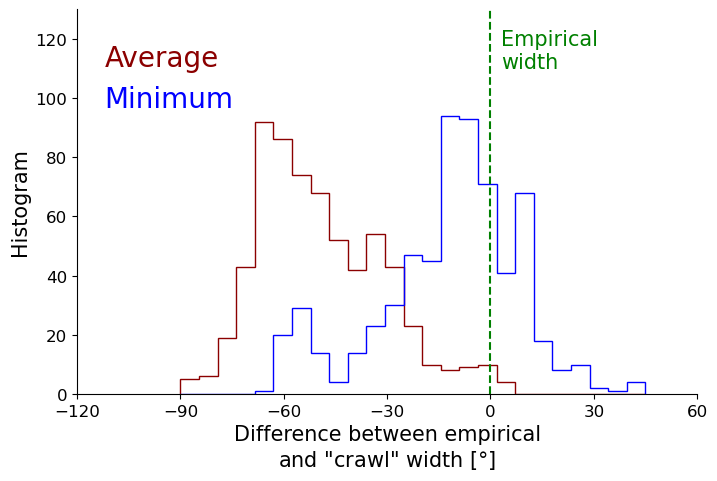

In [112]:
plt.figure(figsize = (8,5))
plt.hist(optima_widths_avg-bio_fwhms.mean(axis=1), \
        bins = 25, range = (-90, 45), histtype = 'step', color = 'darkred')
plt.plot([0],[0], color = 'darkred', label = 'Average')
plt.hist(optima_widths_min-bio_fwhms.mean(axis=1), \
        bins = 25, range = (-90, 45), histtype = 'step', color = 'blue')
plt.plot([0],[0], color = 'blue', label = 'Minimum')

plt.axvline(0, color = 'green', linestyle = 'dashed')
plt.text(3, 110, 'Empirical\nwidth', color = 'green', size = 15)
plt.xlim(-90, 45)
plt.ylim(0,130)
plt.xticks(np.arange(-120, 61, 30))
plt.yticks(np.arange(0, 121, 20))
# mpl.axes.Axes.tick_params(labelsize)
plt.tick_params(which='both', labelsize=12)

plt.xlabel('Difference between empirical\n'+r'and "crawl" width [$\degree$]', \
                         size = 15)
plt.ylabel('Histogram',size = 15)

plt.legend(handlelength = 0, labelcolor = 'linecolor', frameon=0, loc=(-0.01, 0.7), fontsize = 20)
plt.savefig('C:/Users/Carlo PARIS/Desktop/Thesis/PhD presentation/Images/Width_Diff_optima_crawl.png',\
           bbox_inches ='tight', dpi=300)

In [5]:
##  ORIGINAL ARRAYS
title_add = 'original_array'

# NB: Do some smoothing !  -> savgol_filter or simple 3-pt filtering
ssi_min_filt = np.copy(data_dict['all_ssis'].min(axis=2))
ssi_avg_filt = np.copy(data_dict['all_ssis'].mean(axis=2))

In [34]:
# GET OPTIMA FOLLOWING MIN_SSI CURVE
optima_min = []

cutoff_width = 180

for i,ssi_evol_raw in enumerate(data_dict['all_ssis'].min(axis=2)):
    ssi_min_filt = SMOOTH(ssi_evol_raw,3)
    absolute_last = len(ssi_min_filt)-1
#     last = min(np.where(np.any(data_dict['all_quad_fwhm'][i]<=cutoff_width, axis=1))[0][-1], ssi_min_filt.shape[1]-1)
    last = min(np.where(data_dict['all_quad_fwhm'][i].mean(axis=1)<=cutoff_width)[0][-1], absolute_last)
    go1=3
    while go1>0 and last>0:
        minSSI_diff = (ssi_min_filt[last-1]-ssi_min_filt[last])
#         avgSSI_diff = (ssi_avg_filt[i,last-1]-ssi_avg_filt[i,last])        
        if minSSI_diff <= 0:#ssi_evol_raw.min(axis=1).std(axis=0)/100:
            go1 -= 1
#         else:
#             go1 = 3
        if not go1:
            optima_min += [last+2]
        last -= 1

optima_min = np.array(optima_min)

perc_loss_maxmin_crawl = np.array([data_dict['all_ssis'].min(axis=2)[i,el] \
                        for i,el in enumerate(optima_min)])\
                        -data_dict['all_ssis'].min(axis=2)[:,bio_idx]
optima_widths_min = np.array([data_dict['all_quad_fwhm'][i,el].mean() for i,el in enumerate(optima_min)])

# large_quad = np.squeeze(np.argwhere(data_dict['all_quad_fwhm'][:,bio_idx,:].mean(axis=1)-optima_widths<-50))
# print(large_quad.shape)

# GET OPTIMA FILLOWING AVG_SSI CURVE


optima_avg = []

for i,ssi_evol_raw in enumerate(data_dict['all_ssis'].mean(axis=2)):
    ssi_avg_filt = SMOOTH(ssi_evol_raw,3)
    absolute_last = len(ssi_avg_filt)-1
#     last = min(np.where(np.all(data_dict['all_quad_fwhm'][i]<=cutoff_width, axis=1))[0][-1], ssi_min_filt.shape[1]-1)
    last = min(np.where(data_dict['all_quad_fwhm'][i].mean(axis=1)<=cutoff_width)[0][-1], absolute_last)
    
    go1=3
    while go1>0 and last>0:
#         minSSI_diff = (ssi_min_filt[i,last-1]-ssi_min_filt[i,last])
        avgSSI_diff = (ssi_avg_filt[last-1]-ssi_avg_filt[last])        
        if avgSSI_diff <= 0:#ssi_evol_raw.mean(axis=1).std(axis=0)/100:
            go1 -= 1
#         else:
#             go1 = 3
        if not go1:
            optima_avg += [last+2]
        last -= 1
        
optima_avg = np.array(optima_avg)

perc_loss_maxavg_crawl = np.array([data_dict['all_ssis'].mean(axis=2)[i,el] \
                        for i,el in enumerate(optima_avg)])\
                        -data_dict['all_ssis'].mean(axis=2)[:,bio_idx]

optima_widths_avg = np.array([data_dict['all_quad_fwhm'][i,el].mean() for i,el in enumerate(optima_avg)])

In [62]:
print(fwhm.shape)

(648, 56)


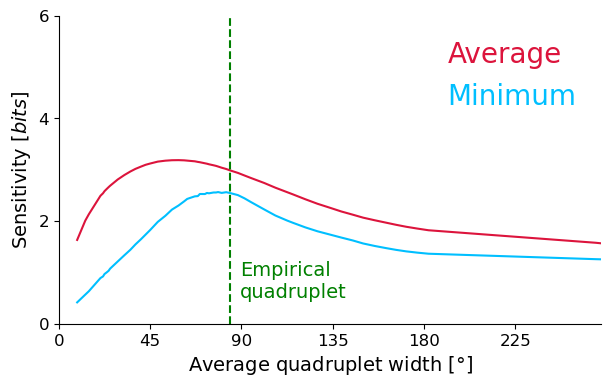

In [78]:
import numpy as np
import matplotlib.pyplot as plt

# --- required inputs extracted from your full script ---
el = 475
# el= example_quads[0]
i = 0

fwhm_mean = data_dict['all_quad_fwhm'].mean(axis=2)[el]
ssi_mean = data_dict['all_ssis'][el].mean(axis=1)
ssi_min  = data_dict['all_ssis'][el].min(axis=1)

bio_x  = fwhm_mean[bio_idx]
ymax   = 6
last   = min(np.where(data_dict['all_quad_fwhm'][el].mean(axis=1) <= cutoff_width)[0][-1],
             data_dict['all_quad_fwhm'].shape[1]-1)

# star markers
opt_x_min  = data_dict['all_quad_fwhm'].mean(axis=2)[el, optima_min[el]]
opt_y_min  = data_dict['all_ssis'].min(axis=2)[el, optima_min[el]]
opt_x_avg  = data_dict['all_quad_fwhm'].mean(axis=2)[el, optima_avg[el]]
opt_y_avg  = data_dict['all_ssis'].mean(axis=2)[el, optima_avg[el]]

# crawl arrow position
x_arrow = cutoff_width + 5
y_arrow = data_dict['all_ssis'].mean(axis=2)[el, last]

# color choices
colors = ['deepskyblue', 'crimson']

# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7,4))

# average and minimum sensitivity curves
ax.plot(fwhm_mean, ssi_mean, color='crimson', label='Average')
ax.plot(fwhm_mean, ssi_min,  color='deepskyblue', label='Minimum')

# empirical quadruplet line
ax.axvline(bio_x, linestyle='dashed', color='green')
ax.text(bio_x+5, 0.5, 'Empirical\nquadruplet', color='green', size=14)

# star markers (min and avg)
# ax.scatter(opt_x_min, opt_y_min, s=200, marker='*', facecolor='white',
#            linewidth=2, color=colors[0])
# ax.scatter(opt_x_avg, opt_y_avg, s=200, marker='*', facecolor='white',
#            linewidth=2, color=colors[1])

# legend only for i=0 panel
ax.legend(frameon=False, fontsize=20, handlelength = 0, labelcolor = 'linecolor')

# arrow + helper line
# ax.annotate('Crawl', xy=(x_arrow-30, y_arrow+0.8),
#             xytext=(x_arrow-3, y_arrow+0.1),
#             arrowprops=dict(arrowstyle='->', lw=2), fontsize=12)
# ax.plot([x_arrow-5.5, x_arrow-5+3],
#         [y_arrow+0.5, y_arrow+0.5+0.7], color='k', lw=2)

# axis formatting
ax.set_xlim(0, fwhms.mean(axis=2).max())
ax.set_ylim(0, ymax)
ax.set_yticks(np.arange(0, ymax+0.01, 2))
ax.set_xticks(np.arange(0, fwhms.mean(axis=2).max(), 45))

ax.set_xlabel(r'Average quadruplet width [$\degree$]', fontsize=14)
ax.set_ylabel(r'Sensitivity [$bits$]', fontsize=14)
ax.tick_params(labelsize=12)

fig.savefig('C:/Users/Carlo PARIS/Desktop/Thesis/PhD presentation/Images/Quad1_ex_Min&Avg.png', \
            bbox_inches = 'tight', dpi = 400)

201 201
125 125


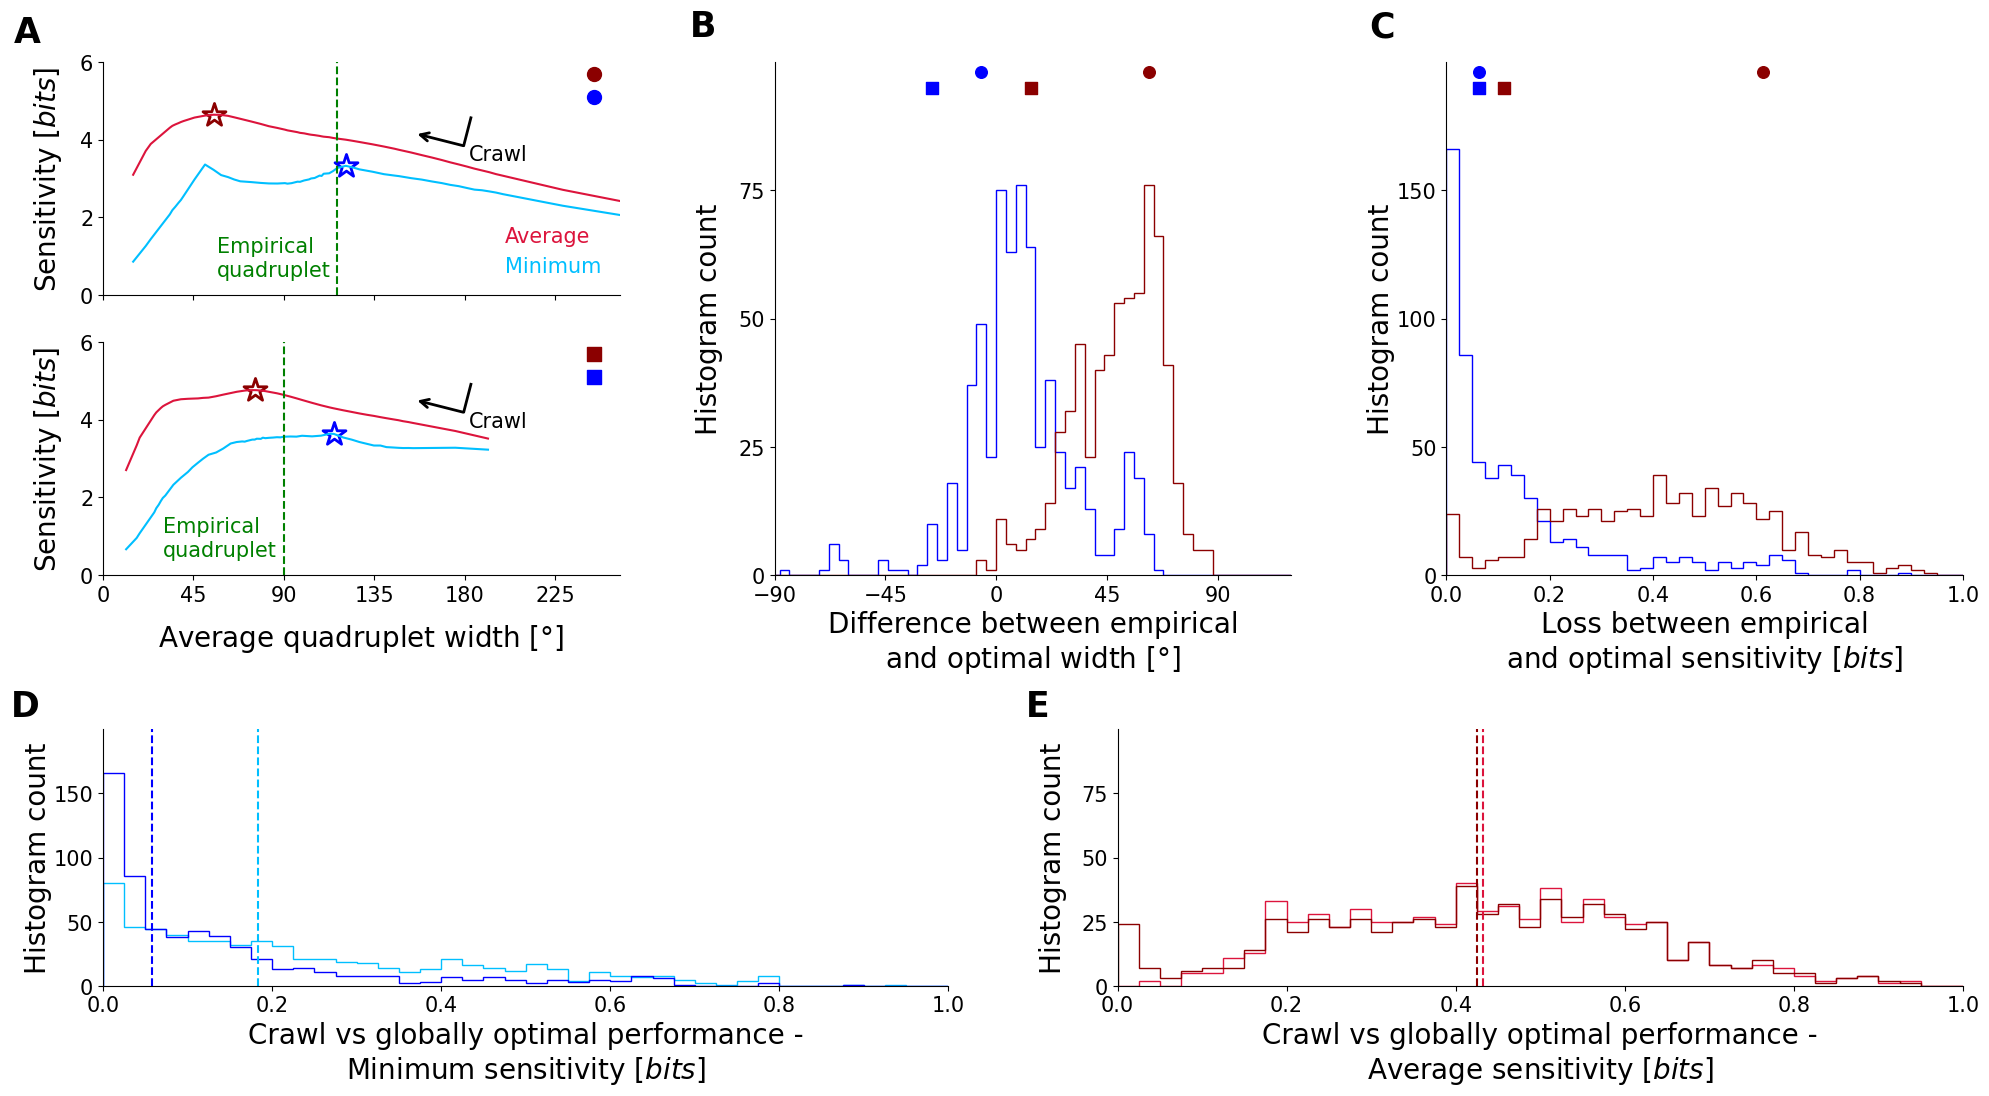

In [7]:
fig = plt.figure(figsize = (24, 12))
# gs = gridspec.GridSpec(5,3, wspace = 0.5, hspace = 0.2, height_ratios=(4,4,1,6,6))
gs = fig.add_gridspec(2,1, hspace = 0.4, height_ratios = (8,4))
gs01 = gs[0].subgridspec(2,3, wspace = 0.3)
gs02 = gs[1].subgridspec(1,2, wspace = 0.2)


ax_q1 = fig.add_subplot(gs01[0,0])
ax_q2 = fig.add_subplot(gs01[1,0])

ax_gl_w_hist = fig.add_subplot(gs01[:,1])
ax_gl_loss_hist = fig.add_subplot(gs01[:,2])

ax_fig3_v_crawl_sc_min = fig.add_subplot(gs02[0])
ax_fig3_v_crawl_sc_avg = fig.add_subplot(gs02[1])

colors = ['blue', 'darkred']
cutoff_width = 180

for i,el in enumerate(example_quads):
    print(example_quads[i], el)
    last = min(np.where(data_dict['all_quad_fwhm'][el].mean(axis=1)\
                    <=cutoff_width)[0][-1], data_dict['all_quad_fwhm'].shape[1]-1)
    
    ymax = 6
    bio_fwhm_mean = fwhms[i].mean(axis=1)[bio_idx]
    bio_fwhm_std = fwhms[i].std(axis=1)[bio_idx]
    
    ax = [ax_q1, ax_q2][i]
    ax.plot(fwhms[i].mean(axis=1), data_dict['all_ssis'][el].mean(axis=1), \
            color = 'crimson', label = 'Average')
    ax.plot(fwhms[i].mean(axis=1), data_dict['all_ssis'][el].min(axis=1), \
            color = 'deepskyblue', label = 'Minimum')   
    ax.axvline(fwhms[i].mean(axis=1)[bio_idx], linestyle = 'dashed', color = 'green')
    ax.text(fwhms[i].mean(axis=1)[bio_idx]-60, 0.5, \
            'Empirical\nquadruplet', color = 'green', size = 15, transform = ax.transData)

    ax.scatter(data_dict['all_quad_fwhm'].mean(axis=2)[example_quads[i],\
                 optima_min[example_quads[i]]],
              data_dict['all_ssis'].min(axis=2)[example_quads[i],\
                 optima_min[example_quads[i]]], s=300, marker='*',\
              facecolor = 'white', linewidth = 2, color = colors[0])
    ax.scatter(data_dict['all_quad_fwhm'].mean(axis=2)[example_quads[i],\
                 optima_avg[example_quads[i]]],
              data_dict['all_ssis'].mean(axis=2)[example_quads[i],\
                 optima_avg[example_quads[i]]], s=300, marker='*',\
              facecolor = 'white', linewidth = 2, color = colors[1])
    if i==0:
        ax.legend(handlelength = 0, frameon = 0, labelcolor = 'linecolor', \
                  loc = 'lower right', fontsize = 15)

    ax.tick_params(labelsize = 15)
    ax.set_xticks(np.arange(0,fwhms.mean(axis=2).max(), 45))
    ax.set_xlabel(r'Average quadruplet width [$\degree$]', size = 20)
    ax.xaxis.set_label_coords(0.5, -0.2)
    ax.yaxis.set_label_coords(-0.075, 0.5)
    
    if i==0:
        ax.set_xticklabels([])
        ax.set_xlabel('')
        
    ax.set_yticks(np.arange(0,ymax*1.01, 2))
    ax.set_xlim(0,fwhms.mean(axis=2).max())
    ax.set_ylim(0,ymax)
    ax.set_ylabel(r'Sensitivity [$bits$]', size = 20)
    
    ax.scatter(0.95*fwhms.mean(axis=2).max(), 0.95*ymax, marker = scatter_marker[i], color = colors[1], s=100)
    ax.scatter(0.95*fwhms.mean(axis=2).max(), 0.85*ymax, marker = scatter_marker[i], color = colors[0], s=100)
    
    
    x_arrow = cutoff_width+5
    y_arrow = data_dict['all_ssis'].mean(axis=2)[el,last]
    
    ax.annotate('Crawl', xy = (x_arrow-30, y_arrow+0.8), xytext= (x_arrow-3, y_arrow+0.1),\
                arrowprops = dict(arrowstyle = '->', facecolor='black', lw=2),\
                fontsize = 15)
    ax.plot([x_arrow-5.5, x_arrow-5+3], [y_arrow+0.5, y_arrow+0.5+0.7], color = 'k', lw=2)
    
    if i==0:
        ax.text(-45, 6.5, r'$\bf{A}$', fontsize = 25, transform = ax.transData)


min_w_diffs = data_dict['all_quad_fwhm'].mean(axis=2)[:,bio_idx]-optima_widths_min
avg_w_diffs = data_dict['all_quad_fwhm'].mean(axis=2)[:,bio_idx]-optima_widths_avg
    
min_w_hist = ax_gl_w_hist.hist(min_w_diffs, range = (-120,120), bins = 60, histtype = 'step', color = colors[0])
avg_w_hist = ax_gl_w_hist.hist(avg_w_diffs, range = (-120,120), bins = 60, histtype = 'step', color = colors[1])


decreaseMin = 0
for i,el in enumerate(example_quads):

    ax_gl_w_hist.scatter((min_w_hist[1][np.where(min_w_diffs[el]<=min_w_hist[1])[0][0]]+\
                min_w_hist[1][np.where(min_w_diffs[el]<=min_w_hist[1])[0][0]-1])/2, 98-decreaseMin,\
              marker = scatter_marker[i], color = colors[0], s= 70)
    
    ax_gl_w_hist.scatter((avg_w_hist[1][np.where(avg_w_diffs[el]<=avg_w_hist[1])[0][0]]+\
                avg_w_hist[1][np.where(avg_w_diffs[el]<=avg_w_hist[1])[0][0]-1])/2, 98-decreaseMin,\
              marker = scatter_marker[i], color = colors[1], s= 70)

    decreaseMin += 3
    

ax_gl_w_hist.set_xticks(np.arange(-90,91,45))
ax_gl_w_hist.set_yticks(np.arange(0,100,25))
ax_gl_w_hist.set_xlim(-90,120)
ax_gl_w_hist.set_ylim(0,100)
ax_gl_w_hist.set_xlabel('Difference between empirical\n'+r'and optimal width [$\degree$]', \
                         size = 20)
ax_gl_w_hist.yaxis.set_label_coords(-0.1, 0.5)
ax_gl_w_hist.set_ylabel('Histogram count', size = 20)
ax_gl_w_hist.tick_params(labelsize = 15)
ax_gl_w_hist.text(-125, 105, r'$\bf{B}$', fontsize = 25, \
                  transform = ax_gl_w_hist.transData)


loc_loss_min = ax_gl_loss_hist.hist(perc_loss_maxmin_crawl, range=(0,1), bins = 40,\
                              histtype= 'step', color = colors[0])
loc_loss_avg = ax_gl_loss_hist.hist(perc_loss_maxavg_crawl, range=(0,1), bins = 40,\
                              histtype= 'step', color = colors[1])
ax_gl_loss_hist.set_xticks(np.arange(0,1.1, 0.2), labelsize = 20)
ax_gl_loss_hist.set_yticks(np.arange(0,200, 50))
ax_gl_loss_hist.set_xlim(0,1)
ax_gl_loss_hist.set_ylim(0,200)
ax_gl_loss_hist.yaxis.set_label_coords(-0.1, 0.5)
ax_gl_loss_hist.set_ylabel('Histogram count', size = 20)
ax_gl_loss_hist.set_xlabel('Loss between empirical\n'+\
                            r'and optimal sensitivity [$bits$]', size = 20)
ax_gl_loss_hist.tick_params(labelsize = 15)

decreaseMin = 0
for i,el in enumerate(example_quads):
    
    ax_gl_loss_hist.scatter((loc_loss_min[1][np.where(perc_loss_maxmin_crawl[el]<=loc_loss_min[1])[0][0]]+\
                loc_loss_min[1][np.where(perc_loss_maxmin_crawl[el]<=loc_loss_min[1])[0][0]-1])/2, 196-decreaseMin,\
              marker = scatter_marker[i], color = colors[0], s= 70)
    
    ax_gl_loss_hist.scatter((loc_loss_avg[1][np.where(perc_loss_maxavg_crawl[el]<=loc_loss_avg[1])[0][0]]+\
                loc_loss_avg[1][np.where(perc_loss_maxavg_crawl[el]<=loc_loss_avg[1])[0][0]-1])/2, 196-decreaseMin,\
              marker = scatter_marker[i], color = colors[1], s= 70)

    decreaseMin += 6
ax_gl_loss_hist.text(-0.15, 210, r'$\bf{C}$', fontsize = 25, \
                  transform = ax_gl_loss_hist.transData)
    
ax_fig3_v_crawl_sc_min.tick_params(labelsize = 15)
ax_fig3_v_crawl_sc_avg.tick_params(labelsize = 15)
ax_fig3_v_crawl_sc_min.yaxis.set_label_coords(-0.06, 0.5)



ax_fig3_v_crawl_sc_min.hist(perc_loss_maxmin, range = (0,1),\
                            bins = 40, color = 'deepskyblue', histtype = 'step')
ax_fig3_v_crawl_sc_min.hist(perc_loss_maxmin_crawl, range = (0,1),\
                            bins = 40, color = colors[0], histtype = 'step')
ax_fig3_v_crawl_sc_min.axvline(np.median(perc_loss_maxmin), linestyle = 'dashed', \
                              color = 'deepskyblue')
ax_fig3_v_crawl_sc_min.axvline(np.median(perc_loss_maxmin_crawl), linestyle = 'dashed', \
                              color = colors[0])
ax_fig3_v_crawl_sc_min.set_xticks(np.arange(0,1.1, 0.2))
ax_fig3_v_crawl_sc_min.set_yticks(np.arange(0,200, 50))
ax_fig3_v_crawl_sc_min.set_xlim(0,1)
ax_fig3_v_crawl_sc_min.set_ylim(0,200)
ax_fig3_v_crawl_sc_min.set_xlabel('Crawl vs globally optimal performance -\nMinimum sensitivity '+'[$bits$]', size = 20)
ax_fig3_v_crawl_sc_min.set_ylabel('Histogram count', size = 20)

ax_fig3_v_crawl_sc_min.text(-0.11, 210, r'$\bf{D}$', fontsize = 25, \
                  transform = ax_fig3_v_crawl_sc_min.transData)

ax_fig3_v_crawl_sc_avg.hist(perc_loss_maxavg, range = (0,1),\
                            bins = 40, color = 'crimson', histtype = 'step')
ax_fig3_v_crawl_sc_avg.hist(perc_loss_maxavg_crawl, range = (0,1),\
                            bins = 40, color = colors[1], histtype = 'step') 

ax_fig3_v_crawl_sc_avg.axvline(np.median(perc_loss_maxavg), linestyle = 'dashed', \
                              color = 'crimson')
ax_fig3_v_crawl_sc_avg.axvline(np.median(perc_loss_maxavg_crawl), linestyle = 'dashed', \
                              color = colors[1])

ax_fig3_v_crawl_sc_avg.set_xticks(np.arange(0,1.1, 0.2))
ax_fig3_v_crawl_sc_avg.set_yticks(np.arange(0,100,25))
ax_fig3_v_crawl_sc_avg.set_xlim(0,1)
ax_fig3_v_crawl_sc_avg.set_ylim(0,100)
ax_fig3_v_crawl_sc_avg.set_xlabel('Crawl vs globally optimal performance -\nAverage sensitivity '+r'[$bits$]', size = 20)
ax_fig3_v_crawl_sc_avg.text(-0.11, 105, r'$\bf{E}$', fontsize = 25, \
                  transform = ax_fig3_v_crawl_sc_avg.transData)
ax_fig3_v_crawl_sc_avg.yaxis.set_label_coords(-0.06, 0.5)
ax_fig3_v_crawl_sc_avg.set_ylabel('Histogram count', size = 20)


plt.savefig('Paper_Figure_4.jpg', bbox_inches = 'tight', dpi=300)

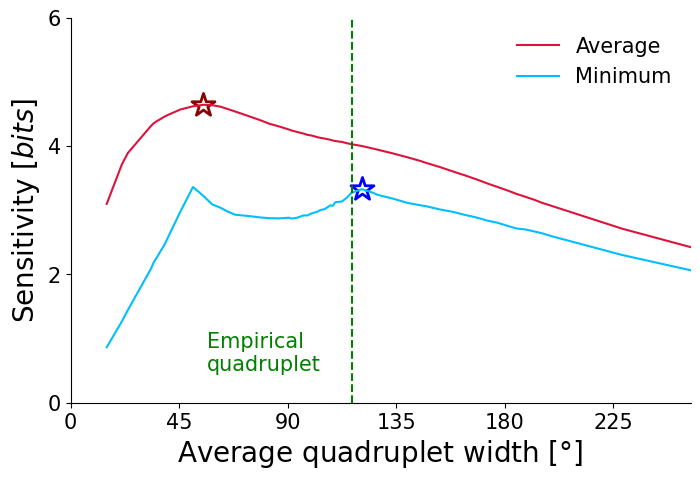

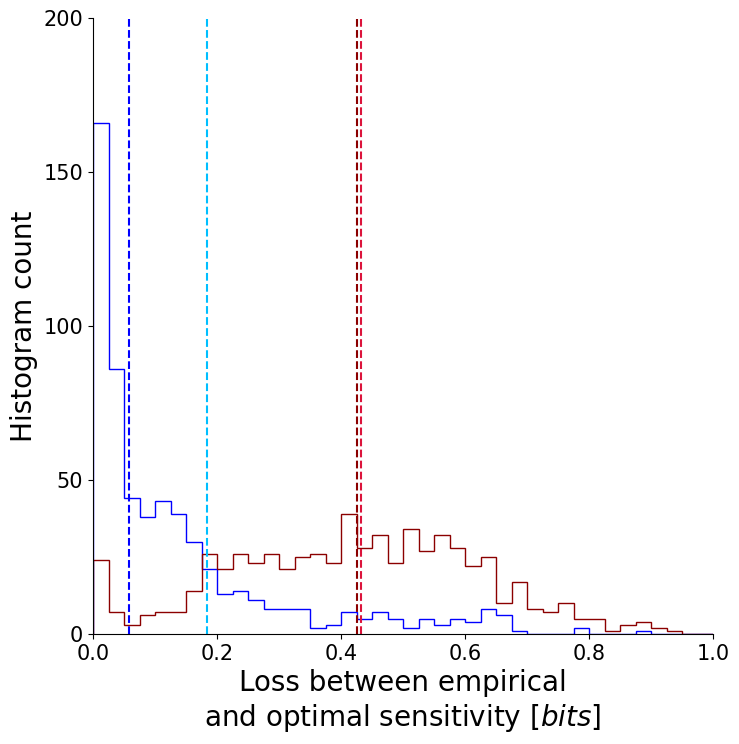

In [27]:
import matplotlib.pyplot as plt
import numpy as np

colors = ['blue', 'darkred']
i = 0  # example quad index
ymax = 6
cutoff_width = 200
# ------------------------
# FIGURE 1: ax_q1
# ------------------------
fig1 = plt.figure(figsize=(8,5))
ax_q1 = fig1.add_subplot(1,1,1)

ax_q1.plot(fwhms[i].mean(axis=1), data_dict['all_ssis'][example_quads[i]].mean(axis=1),
           color='crimson', label='Average')
ax_q1.plot(fwhms[i].mean(axis=1), data_dict['all_ssis'][example_quads[i]].min(axis=1),
           color='deepskyblue', label='Minimum')

ax_q1.axvline(fwhms[i].mean(axis=1)[bio_idx], linestyle='dashed', color='green')
ax_q1.text(fwhms[i].mean(axis=1)[bio_idx]-60, 0.5, 'Empirical\nquadruplet',
           color='green', size=15, transform=ax_q1.transData)

ax_q1.set_xlabel(r'Average quadruplet width [$\degree$]', size=20)
ax_q1.set_ylabel(r'Sensitivity [$bits$]', size=20)
ax_q1.set_xlim(0, fwhms.mean(axis=2).max())
ax_q1.set_ylim(0, ymax)
ax_q1.set_xticks(np.arange(0,fwhms.mean(axis=2).max(),45))
ax_q1.set_yticks(np.arange(0, ymax*1.01, 2))
ax_q1.tick_params(labelsize=15)
ax_q1.legend(frameon=False, fontsize=15)

# Scatter stars for min and avg optima
ax_q1.scatter(
    data_dict['all_quad_fwhm'].mean(axis=2)[example_quads[i], optima_min[example_quads[i]]],
    data_dict['all_ssis'].min(axis=2)[example_quads[i], optima_min[example_quads[i]]],
    s=300, marker='*', facecolor='white', linewidth=2, color=colors[0]
)
ax_q1.scatter(
    data_dict['all_quad_fwhm'].mean(axis=2)[example_quads[i], optima_avg[example_quads[i]]],
    data_dict['all_ssis'].mean(axis=2)[example_quads[i], optima_avg[example_quads[i]]],
    s=300, marker='*', facecolor='white', linewidth=2, color=colors[1]
)

# # Arrow annotation for "Crawl"
# last = min(np.where(data_dict['all_quad_fwhm'][example_quads[i]].mean(axis=1) <= cutoff_width)[0][-1],
#            data_dict['all_quad_fwhm'].shape[1]-1)
# x_arrow = cutoff_width + 5
# y_arrow = data_dict['all_ssis'].mean(axis=2)[example_quads[i], last]
# ax_q1.annotate('Crawl',
#                xy=(x_arrow-30, y_arrow+0.8),
#                xytext=(x_arrow-3, y_arrow+0.1),
#                arrowprops=dict(arrowstyle='->', facecolor='black', lw=2),
#                fontsize=15)
# ax_q1.plot([x_arrow-5.4, x_arrow-5+3], [y_arrow+0.5-0.05, y_arrow+0.5+0.7], color='k', lw=2)

# plt.tight_layout()
# plt.show()
fig1.savefig('C:/Users/Carlo PARIS/Desktop/Thesis/PhD presentation/Images/Crawl_SSI_curve.png', \
            bbox_inches = 'tight', dpi = 400)

# ------------------------
# FIGURE 2: ax_gl_loss_hist
# ------------------------
fig2 = plt.figure(figsize=(8,8))
ax_gl_loss_hist = fig2.add_subplot(1,1,1)

loc_loss_min = ax_gl_loss_hist.hist(perc_loss_maxmin_crawl, range=(0,1), bins=40,
                                   histtype='step', color='blue')
loc_loss_avg = ax_gl_loss_hist.hist(perc_loss_maxavg_crawl, range=(0,1), bins=40,
                                   histtype='step', color='darkred')

ax_gl_loss_hist.axvline(np.median(perc_loss_maxmin_crawl), linestyle = 'dashed', color = 'blue')
ax_gl_loss_hist.axvline(np.median(perc_loss_maxavg_crawl), linestyle = 'dashed', color = 'darkred')

ax_gl_loss_hist.axvline(np.median(perc_loss_maxmin), linestyle = 'dashed', color = 'deepskyblue')
ax_gl_loss_hist.axvline(np.median(perc_loss_maxavg), linestyle = 'dashed', color = 'crimson')

ax_gl_loss_hist.set_xlabel('Loss between empirical\nand optimal sensitivity [$bits$]', size=20)
ax_gl_loss_hist.set_ylabel('Histogram count', size=20)
ax_gl_loss_hist.set_xlim(0,1)
ax_gl_loss_hist.set_ylim(0,200)
ax_gl_loss_hist.set_xticks(np.arange(0,1.1,0.2))
ax_gl_loss_hist.set_yticks(np.arange(0,201,50))
ax_gl_loss_hist.tick_params(labelsize=15)

# # Annotate example quads
# decreaseMin = 0
# for i, el in enumerate(example_quads):
#     ax_gl_loss_hist.scatter(
#         (loc_loss_min[1][np.where(perc_loss_maxmin_crawl[el]<=loc_loss_min[1])[0][0]] +
#          loc_loss_min[1][np.where(perc_loss_maxmin_crawl[el]<=loc_loss_min[1])[0][0]-1])/2,
#         196-decreaseMin, marker='o', color='blue', s=70
#     )
#     ax_gl_loss_hist.scatter(
#         (loc_loss_avg[1][np.where(perc_loss_maxavg_crawl[el]<=loc_loss_avg[1])[0][0]] +
#          loc_loss_avg[1][np.where(perc_loss_maxavg_crawl[el]<=loc_loss_avg[1])[0][0]-1])/2,
#         196-decreaseMin, marker='o', color='darkred', s=70
#     )
#     decreaseMin += 6

# plt.tight_layout()
# plt.show()
fig2.savefig('C:/Users/Carlo PARIS/Desktop/Thesis/PhD presentation/Images/Loss_histogram_crawl_median_comparison.png', \
            bbox_inches = 'tight', dpi = 400)